## Importar as bibliotecas


- **pandas**: trabalha com tabelas (como um Excel dentro do Python)
- **numpy**: faz contas
- **matplotlib** e **seaborn**: desenham gráficos
- **scikit-learn**: tem o algoritmo K-Means
- **mlxtend**: encontra produtos comprados juntos

A linha `!pip install mlxtend` instala a única biblioteca que normalmente não vem instalada.

In [2]:
!pip install mlxtend -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from mlxtend.frequent_patterns import apriori, association_rules

# Deixa os gráficos com um visual mais bonito
sns.set_theme(style='whitegrid')

# Mostra números com 2 casas decimais
pd.set_option('display.float_format', '{:,.2f}'.format)


## Passo 1: Conhecer os dados

Vamos ler o arquivo e olhar as primeiras linhas.

> O arquivo usa acentos do padrão europeu, por isso usamos `encoding='ISO-8859-1'`.
> Lemos `CustomerID` como texto (`str`) porque é um código, não um número para fazer contas.

In [4]:
df = pd.read_csv('data.csv', encoding='ISO-8859-1', dtype={'CustomerID': str, 'InvoiceNo': str})

print('Linhas e colunas:', df.shape)
df.head()

Linhas e colunas: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


## **O que significa cada coluna:**


 **InvoiceNo** : Número da fatura (pedido). Se começa com **C**, é um **cancelamento**

**StockCode** : Código do produto

**Description**: Nome do produto

**Quantity**: Quantidade comprada

 **InvoiceDate** : Data e hora da compra

**UnitPrice**: Preço de uma unidade (em libras **£**)

**CustomerID** : Código do cliente

**Country**: País do cliente


In [5]:
# Tipos de dado de cada coluna, a quantidade de linhas e colunas, valores preenchidos, e de Dataframe usado.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [6]:
# Resumo estatístico das colunas numéricas
df.describe()

,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


Existem **quantidades negativas** e **preços negativos**, Significa que existe algum problema nos dados.

In [7]:
# Os valores que estão faltando em cada coluna.
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
#Verificando as linhas duplicadas, os cancelamentos, a quatidade negativa e com preço menor ou igual a 0.
print('Linhas duplicadas:', df.duplicated().sum())
print('Linhas de cancelamento (fatura começa com C):', df['InvoiceNo'].str.startswith('C').sum())
print('Linhas com quantidade negativa:', (df['Quantity'] < 0).sum())
print('Linhas com preço zero ou negativo:', (df['UnitPrice'] <= 0).sum())

Linhas duplicadas: 5268
Linhas de cancelamento (fatura começa com C): 9288
Linhas com quantidade negativa: 10624
Linhas com preço zero ou negativo: 2517


**Problemas encontrados:**
1. Cerca de **25% das linhas não têm CustomerID**. Dificulta a analise do perfil do cliente.
2. Há **linhas duplicadas**.
3. Há **cancelamentos** (quantidade negativa).
4. Há **preços zerados** e **ajustes de estoque** (quantidade negativa sem ser cancelamento).

## Passo 2: Limpar e preparar os dados

### 2.1 Remover duplicados

In [9]:
df = df.drop_duplicates()
print('Linhas depois de remover duplicados:', len(df))

Linhas depois de remover duplicados: 536641


### 2.2 Converter a data

A data veio como texto. Convertendo para o tipo *data*, conseguimos extrair mês, dia da semana e hora.

In [10]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceDate'].head()

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]

### 2.3 Marcar os cancelamentos

Criamos uma coluna `Cancelamento` com **True** (verdadeiro) quando a fatura começa com "C".

In [11]:
df['Cancelamento'] = df['InvoiceNo'].str.startswith('C')
df['Cancelamento'].value_counts()

Cancelamento
False    527390
True       9251
Name: count, dtype: int64

### 2.4 Remover linhas que não são vendas de verdade

- Preço **zero ou negativo** podem ser brindes, erros ou ajustes de dividas
- Quantidade negativa **sem** ser cancelamento pode ser estoque ou devolução de produtos com defeito

In [12]:
preco_valido = df['UnitPrice'] > 0
ajuste_estoque = (df['Quantity'] < 0) & (df['Cancelamento'] == False)

df = df[preco_valido & ~ajuste_estoque]   # o símbolo ~ significa "NÃO"
print('Nova quantidade de linhas:', len(df))

Nova quantidade de linhas: 534129


In [13]:
df.describe()

,Quantity,InvoiceDate,UnitPrice
count,"534,129.00",534129,"534,129.00"
mean,9.92,2011-07-04 12:02:01.631403776,4.70
min,"-80,995.00",2010-12-01 08:26:00,0.00
25%,1.00,2011-03-28 11:36:00,1.25
50%,3.00,2011-07-19 15:55:00,2.10
75%,10.00,2011-10-18 17:10:00,4.13
max,"80,995.00",2011-12-09 12:50:00,"38,970.00"
std,216.45,NaN,95.08


### 2.5 Criar novas colunas
A criação de novas colunas serve para ajudar entender o perfil das pessoas que compram no e-commerce.
- **Total** = Quantidade × Preço (valor de cada linha)
- **Mes**, **DiaSemana** e **Hora**: para estudar quando as pessoas compram

In [14]:
df['Total'] = df['Quantity'] * df['UnitPrice']
df['AnoMes'] = df['InvoiceDate'].dt.to_period('M').astype(str)   # ex.: '2011-11'
df['DiaSemana'] = df['InvoiceDate'].dt.dayofweek                 # 0 = segunda ... 6 = domingo
df['Hora'] = df['InvoiceDate'].dt.hour

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Cancelamento,Total,AnoMes,DiaSemana,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,15.30,2010-12,2,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,2010-12,2,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,22.00,2010-12,2,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,2010-12,2,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,2010-12,2,8


In [15]:
#Visulizando as ultimas linhas da tabela.
df.tail(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Cancelamento,Total,AnoMes,DiaSemana,Hora
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680,France,False,15.00,2011-12,4,12
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680,France,False,15.00,2011-12,4,12
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,12680,France,False,15.60,2011-12,4,12
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680,France,False,23.40,2011-12,4,12
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680,France,False,16.60,2011-12,4,12
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,False,10.20,2011-12,4,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,False,12.60,2011-12,4,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,False,16.60,2011-12,4,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,False,16.60,2011-12,4,12
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,False,14.85,2011-12,4,12


### 2.6 Separar vendas e cancelamentos

Aqui vamos separar e ver a quatidade de linhas da coluna vendas e Cancelamento.

In [16]:
vendas = df[df['Cancelamento'] == False]
cancelamentos = df[df['Cancelamento'] == True]

print('Linhas de vendas:', len(vendas))
print('Linhas de cancelamento:', len(cancelamentos))

Linhas de vendas: 524878
Linhas de cancelamento: 9251


### 2.7 Métricas de sucesso (o ponto de partida)

- **Receita**: soma de todas as vendas
- **Ticket médio**: receita ÷ número de pedidos
- **Taxa de cancelamento**: faturas canceladas ÷ total de faturas
- **Recorrência**: % de clientes que compraram 2 vezes ou mais

In [17]:
receita = vendas['Total'].sum()
valor_cancelado = -cancelamentos['Total'].sum()      # o sinal de menos deixa o valor positivo

pedidos = vendas['InvoiceNo'].nunique()              # nunique = conta valores diferentes
faturas_canceladas = cancelamentos['InvoiceNo'].nunique()

ticket_medio = receita / pedidos
taxa_cancelamento = faturas_canceladas / (pedidos + faturas_canceladas) * 100

pedidos_por_cliente = vendas.dropna(subset=['CustomerID']).groupby('CustomerID')['InvoiceNo'].nunique()
recorrencia = (pedidos_por_cliente >= 2).mean() * 100

print(f'Receita total:          £ {receita:,.2f}')
print(f'Valor cancelado:        £ {valor_cancelado:,.2f}')
print(f'Número de pedidos:      {pedidos}')
print(f'Ticket médio:           £ {ticket_medio:,.2f}')
print(f'Taxa de cancelamento:   {taxa_cancelamento:.1f}% das faturas')
print(f'Recorrência:            {recorrencia:.1f}% dos clientes compraram 2+ vezes')

Receita total:          £ 10,642,110.80
Valor cancelado:        £ 893,979.73
Número de pedidos:      19960
Ticket médio:           £ 533.17
Taxa de cancelamento:   16.1% das faturas
Recorrência:            65.6% dos clientes compraram 2+ vezes


## Passo 3: Análise exploratória (EDA)

### 3.1 Vendas ao longo do tempo

**groupby** foi usado para agrupar a coluna mes e ano e **sum**  para somar os valores de cada grupo.

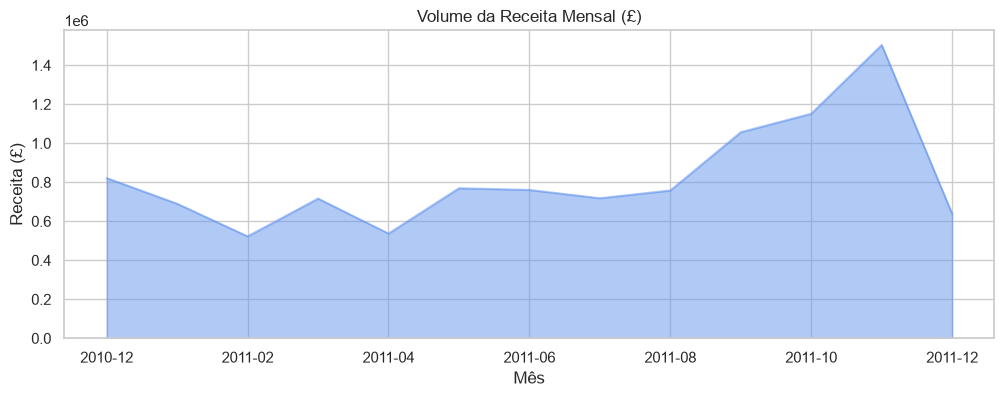

In [18]:
receita_mensal = vendas.groupby('AnoMes')['Total'].sum()

receita_mensal.plot(
    kind='area',
    figsize=(12, 4),
    color='cornflowerblue',
    alpha=0.5
)
plt.title('Volume da Receita Mensal (£)')
plt.xlabel('Mês')
plt.ylabel('Receita (£)')
plt.show()

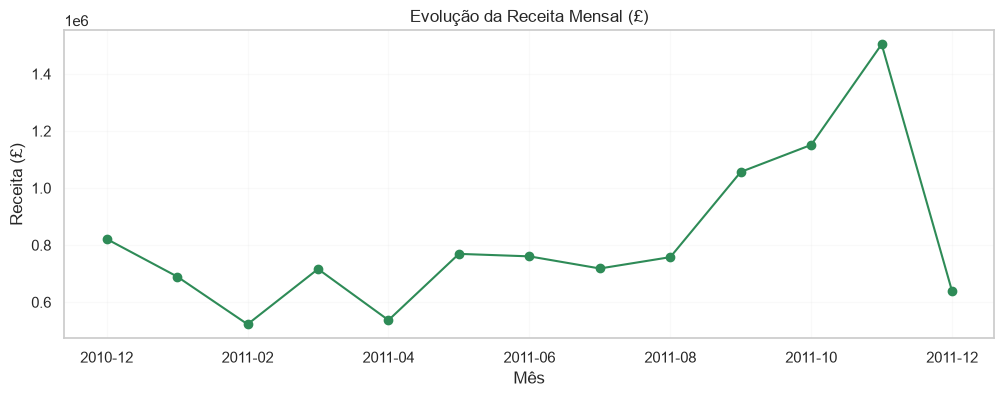

In [19]:
receita_mensal.plot(
    kind='line',
    figsize=(12, 4),
    color='seagreen',
    marker='o'
)
plt.title('Evolução da Receita Mensal (£)')
plt.xlabel('Mês')
plt.ylabel('Receita (£)')
plt.grid(True, alpha=0.1)
plt.show()

**O que vemos:** as vendas sobem muito de **setembro a novembro** (compras de Natal). Dezembro/2011 aparece baixo porque os dados terminam no dia 09/12, com isso não consegue analisar as vendas do mês inteiro.


**Analisando o Dia e a Hora de compra para ver o qual horario e dia que tem maior venda concentrada:**

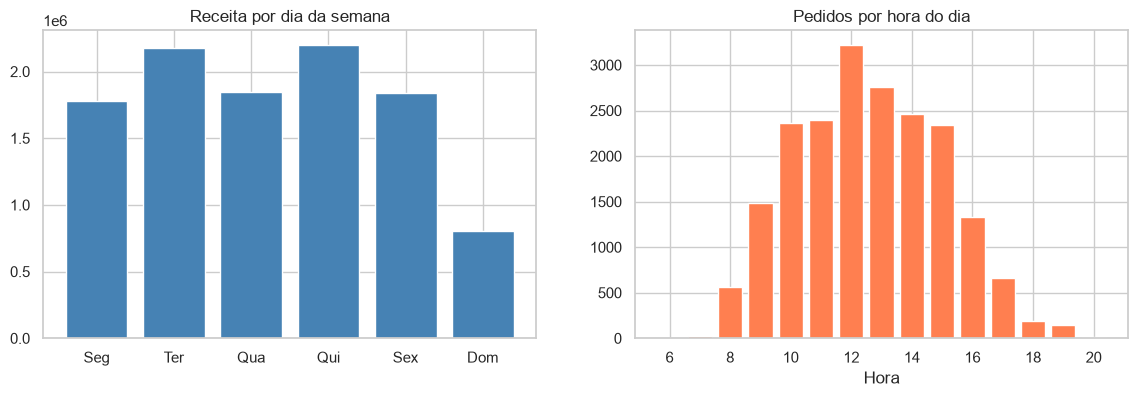

In [20]:
dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
receita_dia = vendas.groupby('DiaSemana')['Total'].sum()
pedidos_hora = vendas.groupby('Hora')['InvoiceNo'].nunique()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))   # 1 linha e 2 gráficos lado a lado

ax[0].bar([dias[d] for d in receita_dia.index], receita_dia.values, color='steelblue')
ax[0].set_title('Receita por dia da semana')

ax[1].bar(pedidos_hora.index, pedidos_hora.values, color='coral')
ax[1].set_title('Pedidos por hora do dia')
ax[1].set_xlabel('Hora')

plt.show()

As vendas concentram-se nos dias úteis, sem registros aos sábados e com menor volume aos domingos. O período entre 10h e 15h apresenta a maior concentração de compras, indicando uma faixa prioritária para otimizar o atendimento e direcionar estratégias comerciais. Já os períodos de menor movimento representam oportunidades para ações promocionais que estimulem as vendas.

### 3.2 Produtos mais vendidos

o comando `nlargest()` serve para encontrar os maiores valores de uma tabela ou coluna, mostrando os registros com os valores mais altos

In [21]:
df.nlargest(10, 'Total')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Cancelamento,Total,AnoMes,DiaSemana,Hora
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,False,"168,469.60",2011-12,4,9
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,False,"77,183.60",2011-01,1,10
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,False,"38,970.00",2011-06,4,15
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,"13,541.33",NaN,United Kingdom,False,"13,541.33",2010-12,1,15
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom,False,"11,062.06",2011-08,4,14
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,"8,142.75",16029,United Kingdom,False,"8,142.75",2011-05,1,13
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450,United Kingdom,False,"7,144.72",2011-09,1,11
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,False,"6,539.40",2011-01,1,12
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749,United Kingdom,False,"6,539.40",2011-04,0,13
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646,Netherlands,False,"4,992.00",2011-10,3,12


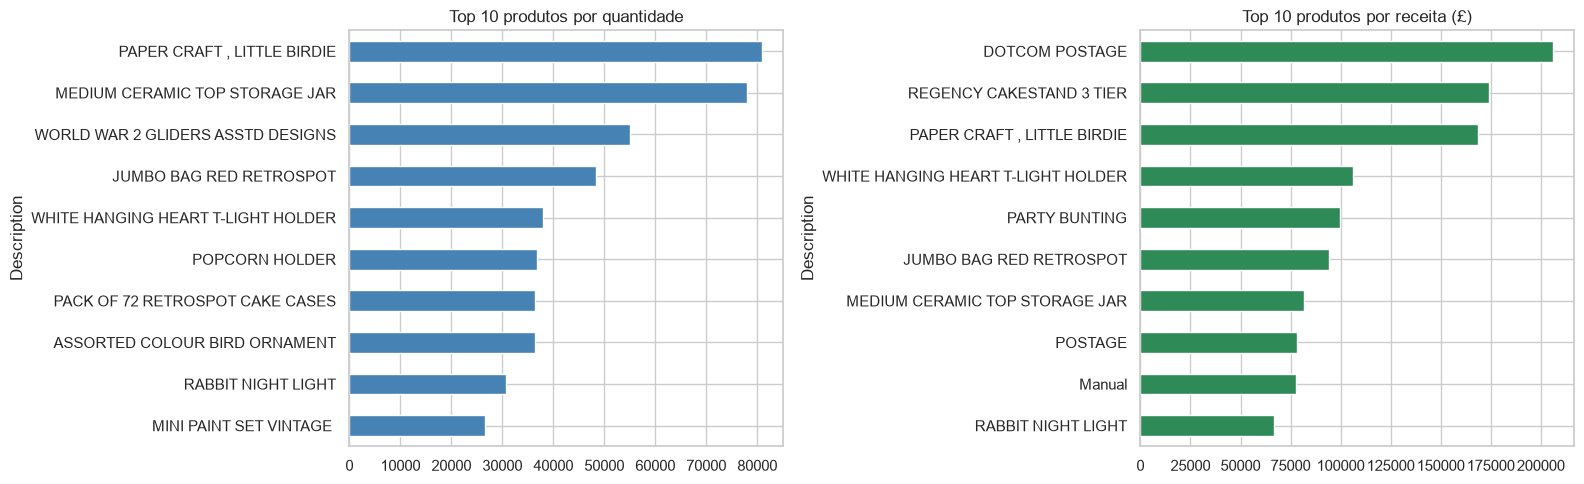

In [22]:
top_quantidade = vendas.groupby('Description')['Quantity'].sum().nlargest(10)
top_receita = vendas.groupby('Description')['Total'].sum().nlargest(10)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
top_quantidade.sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title('Top 10 produtos por quantidade')
top_receita.sort_values().plot(kind='barh', ax=ax[1], color='seagreen')
ax[1].set_title('Top 10 produtos por receita (£)')
plt.tight_layout()
plt.show()

> **Atenção:** o produto "PAPER CRAFT , LITTLE BIRDIE" aparece no topo, mas esse pedido de 80.995 unidades **foi cancelado logo depois**. Sempre desconfie de valores muito altos!

In [23]:
# Quanto cada país representa na receita?
receita_pais = vendas.groupby('Country')['Total'].sum().sort_values(ascending=False)
participacao = receita_pais / receita_pais.sum() * 100
participacao.head(10)

Country
United Kingdom   84.59
Netherlands       2.68
EIRE              2.66
Germany           2.15
France            1.97
Australia         1.30
Spain             0.58
Switzerland       0.54
Belgium           0.39
Sweden            0.36
Name: Total, dtype: float64

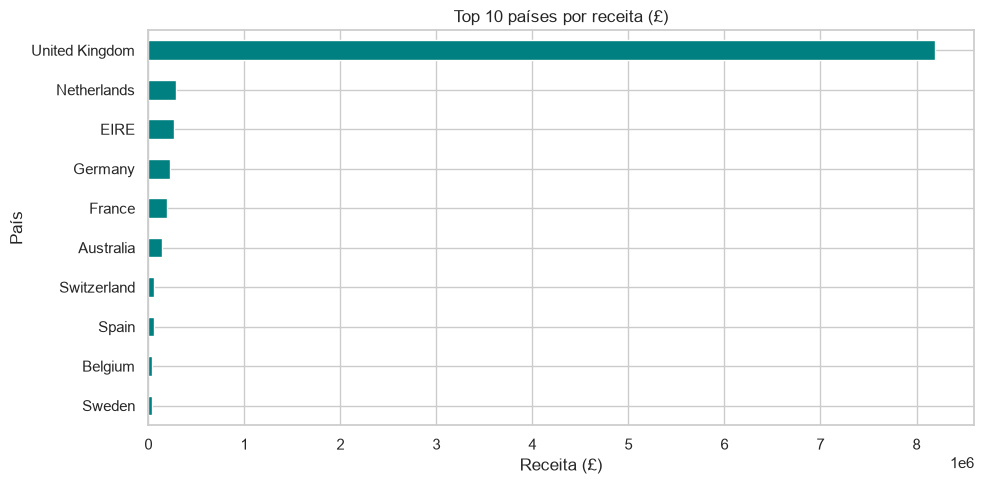

In [24]:
top_paises = (
    df.groupby('Country')['Total']
    .sum()
    .nlargest(10)
)

top_paises.sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    color='teal'
)

plt.title('Top 10 países por receita (£)')
plt.xlabel('Receita (£)')
plt.ylabel('País')
plt.tight_layout()
plt.show()

### 3.3 Produtos comprados juntos (Market Basket Analysis)

### Análise de Cestas de Compras com Apriori

O objetivo desta análise é identificar quais produtos costumam ser comprados juntos em um mesmo pedido, utilizando o algoritmo **Apriori** e as regras de associação.

**Etapas da análise:**

1. **Organização dos dados:** criamos uma tabela em que cada linha representa um pedido e cada coluna corresponde a um produto, indicando com `True` ou `False` se ele está presente na compra.
2. **Identificação de combinações frequentes:** aplicamos o algoritmo Apriori para encontrar conjuntos de produtos que aparecem juntos com frequência.
3. **Geração de regras de associação:** identificamos relações entre produtos, como a tendência de clientes que compram determinado item também adquirirem outro.

**Principais métricas das regras:**

- **Suporte (support):** percentual de pedidos em que os produtos aparecem juntos.
- **Confiança (confidence):** percentual de clientes que também compram o produto B entre aqueles que compraram o produto A.
- **Lift:** mede a força da associação entre dois produtos. Valores acima de 1 indicam uma associação positiva, ou seja, a compra de A está associada a uma maior probabilidade de compra de B.

**Recorte dos dados:** para reduzir o volume de processamento e evitar sobrecarregar o computador, a análise considera apenas os pedidos realizados no Reino Unido.

In [25]:
vendas_uk = vendas[vendas['Country'] == 'United Kingdom']

cesta = vendas_uk.groupby(['InvoiceNo', 'Description'])['Quantity'].sum().unstack(fill_value=0)
cesta = cesta > 0                               # True se o produto está no pedido

# Mantém só produtos que aparecem em pelo menos 2% dos pedidos (deixa mais leve)
cesta = cesta.loc[:, cesta.mean() >= 0.02]
print('Pedidos x produtos:', cesta.shape)

Pedidos x produtos: (18019, 299)


In [26]:
df_uk = df[df['Country'] == 'United Kingdom'].copy()

# Remover registros sem número de pedido ou produto
df_uk = df_uk.dropna(subset=['InvoiceNo', 'Description'])

# Criar a matriz de pedidos e produtos
cesta = (
    df_uk.groupby(['InvoiceNo', 'Description'])['Description']
    .count()
    .unstack(fill_value=0)
)

# Transformar quantidades em presença ou ausência
cesta = cesta > 0

cesta.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,TOADSTOOL BEDSIDE LIGHT,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [27]:
itens_frequentes = apriori(cesta, min_support=0.02, use_colnames=True)
regras = association_rules(itens_frequentes, metric='lift', min_threshold=1)

# Ordena pelas regras mais fortes
regras = regras.sort_values('lift', ascending=False)

# Transforma os conjuntos em texto simples, para ficar fácil de ler
regras['Se comprou'] = regras['antecedents'].apply(lambda x: ', '.join(x))
regras['Também compra'] = regras['consequents'].apply(lambda x: ', '.join(x))

regras[['Se comprou', 'Também compra', 'support', 'confidence', 'lift']].head(10)

,Se comprou,Também compra,support,confidence,lift
92,"ROSES REGENCY TEACUP AND SAUCER , GREEN REGENC...",PINK REGENCY TEACUP AND SAUCER,0.02,0.70,20.33
97,PINK REGENCY TEACUP AND SAUCER,"ROSES REGENCY TEACUP AND SAUCER , GREEN REGENC...",0.02,0.68,20.33
96,GREEN REGENCY TEACUP AND SAUCER,"ROSES REGENCY TEACUP AND SAUCER , PINK REGENCY...",0.02,0.51,19.71
93,"ROSES REGENCY TEACUP AND SAUCER , PINK REGENCY...",GREEN REGENCY TEACUP AND SAUCER,0.02,0.89,19.71
94,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.02,0.85,18.13
95,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.02,0.50,18.13
10,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.03,0.60,17.61
11,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.03,0.80,17.61
8,GARDENERS KNEELING PAD KEEP CALM,GARDENERS KNEELING PAD CUP OF TEA,0.03,0.60,16.93
9,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.03,0.72,16.93


Essa análise permite identificar quais produtos são frequentemente comprados juntos, fornecendo informações estratégicas para desenvolver ações de venda conjunta, criar kits promocionais e recomendar produtos complementares, com o objetivo de aumentar o valor médio dos pedidos e impulsionar o faturamento.


### 3.4 Preços e vendas

Vamos ver como as vendas se dividem por **faixa de preço**. A função `pd.cut` separa os preços em faixas.

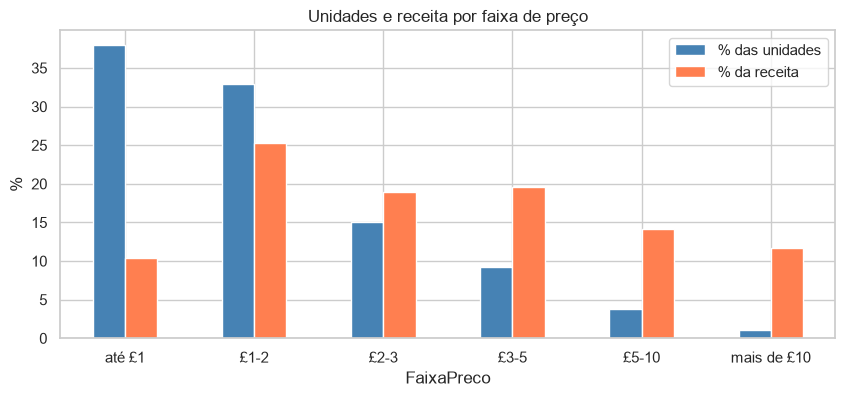

,% das unidades,% da receita
FaixaPreco,,
até £1,37.98,10.38
£1-2,32.96,25.23
£2-3,15.00,18.97
£3-5,9.19,19.55
£5-10,3.77,14.15
mais de £10,1.10,11.72


In [28]:
faixas = [0, 1, 2, 3, 5, 10, 100000]
nomes = ['até £1', '£1-2', '£2-3', '£3-5', '£5-10', 'mais de £10']
vendas_faixa = vendas.copy()
vendas_faixa['FaixaPreco'] = pd.cut(vendas_faixa['UnitPrice'], bins=faixas, labels=nomes)

tabela = vendas_faixa.groupby('FaixaPreco', observed=True)[['Quantity', 'Total']].sum()
tabela_pct = tabela / tabela.sum() * 100
tabela_pct.columns = ['% das unidades', '% da receita']

tabela_pct.plot(kind='bar', figsize=(10, 4), color=['steelblue', 'coral'])
plt.title('Unidades e receita por faixa de preço')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.show()
tabela_pct

**Análise do gráfico:** produtos com preço de até £2 representam aproximadamente 71% das unidades vendidas, mas correspondem a apenas 35,6% da receita. Em contrapartida, produtos acima de £2 representam uma parcela menor das unidades, mas contribuem proporcionalmente mais para o faturamento. Destaca-se a faixa de £3 a £5, que corresponde a cerca de 9,2% das unidades e gera 19,6% da receita. Esses resultados indicam que os produtos de menor preço impulsionam o volume de vendas, enquanto os itens mais caros têm maior participação na geração de receita.

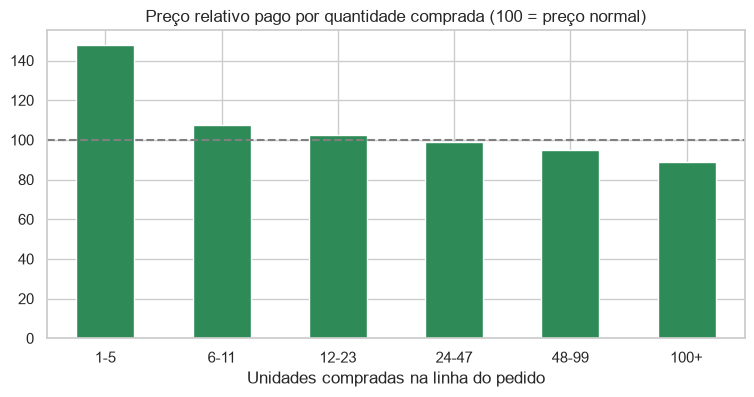

FaixaQtd
1-5     147.86
6-11    107.62
12-23   102.44
24-47    98.84
48-99    94.84
100+     88.66
Name: PrecoRelativo, dtype: float64

In [29]:
precos = vendas.copy()

# Preço mais comum de cada produto
preco_normal = precos.groupby('StockCode')['UnitPrice'].transform('median')
precos['PrecoRelativo'] = precos['UnitPrice'] / preco_normal * 100

# Separa as compras por quantidade de unidades
precos['FaixaQtd'] = pd.cut(precos['Quantity'], bins=[0, 5, 11, 23, 47, 99, 100000],
                            labels=['1-5', '6-11', '12-23', '24-47', '48-99', '100+'])

preco_por_qtd = precos.groupby('FaixaQtd', observed=True)['PrecoRelativo'].mean()

preco_por_qtd.plot(kind='bar', figsize=(9, 4), color='seagreen')
plt.axhline(100, color='gray', linestyle='--')
plt.title('Preço relativo pago por quantidade comprada (100 = preço normal)')
plt.xlabel('Unidades compradas na linha do pedido')
plt.xticks(rotation=0)
plt.show()
preco_por_qtd

**Análise do gráfico:** observa-se uma tendência de redução do preço relativo conforme aumenta a quantidade comprada por pedido. Nas compras de 1 a 5 unidades, o preço relativo médio é de aproximadamente 148, indicando valores cerca de 48% acima da mediana dos respectivos produtos. Já nas compras de 100 unidades ou mais, o índice cai para aproximadamente 89, sugerindo preços cerca de 11% abaixo da mediana. Esse comportamento indica uma possível relação entre maiores quantidades compradas e preços unitários menores. Entretanto, essa relação não comprova a existência de descontos por volume, pois outros fatores também podem influenciar os preços praticados.

### 3.5 Cancelamentos

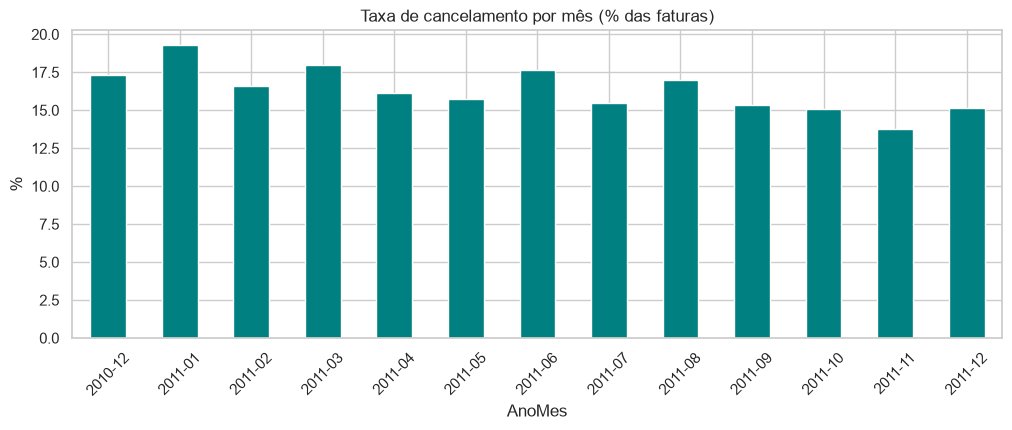

In [30]:
# Taxa de cancelamento por mês
faturas_mes = df.groupby('AnoMes')['InvoiceNo'].nunique()
canceladas_mes = cancelamentos.groupby('AnoMes')['InvoiceNo'].nunique()
taxa_mes = canceladas_mes / faturas_mes * 100

taxa_mes.plot(kind='bar', figsize=(12, 4), color='teal')
plt.title('Taxa de cancelamento por mês (% das faturas)')
plt.ylabel('%')
plt.xticks(rotation=45)
plt.show()

In [31]:
# Os 10 maiores cancelamentos (linhas com mais unidades canceladas)
cancelamentos.sort_values('Quantity').head(10)[['InvoiceNo', 'Description', 'Quantity', 'Total', 'CustomerID', 'InvoiceDate']]

,InvoiceNo,Description,Quantity,Total,CustomerID,InvoiceDate
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,"-168,469.60",16446,2011-12-09 09:27:00
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,"-77,183.60",12346,2011-01-18 10:17:00
4287,C536757,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,-280.80,15838,2010-12-02 14:23:00
160145,C550456,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,"-6,539.40",15749,2011-04-18 13:08:00
160144,C550456,GIN + TONIC DIET METAL SIGN,-2000,"-3,700.00",15749,2011-04-18 13:08:00
160143,C550456,WHITE HANGING HEART T-LIGHT HOLDER,-1930,"-4,921.50",15749,2011-04-18 13:08:00
224419,C556522,HERB MARKER BASIL,-1515,-833.25,16938,2011-06-13 11:21:00
187609,C552995,Manual,-1350,-216.00,18133,2011-05-12 15:19:00
160142,C550456,TEA TIME PARTY BUNTING,-1300,"-3,315.00",15749,2011-04-18 13:08:00
390544,C570556,PINK BLUE FELT CRAFT TRINKET BOX,-1296,"-1,373.76",16029,2011-10-11 11:10:00


In [32]:
# Taxa de cancelamento por país (só países com pelo menos 50 faturas)
faturas_pais = df.groupby('Country')['InvoiceNo'].nunique()
canceladas_pais = cancelamentos.groupby('Country')['InvoiceNo'].nunique()

tabela_pais = pd.DataFrame({'faturas': faturas_pais, 'canceladas': canceladas_pais}).fillna(0)
tabela_pais = tabela_pais[tabela_pais['faturas'] >= 50]
tabela_pais['taxa_%'] = tabela_pais['canceladas'] / tabela_pais['faturas'] * 100
tabela_pais.sort_values('taxa_%', ascending=False).head(10)

,faturas,canceladas,taxa_%
Country,,,
Italy,55,17.00,30.91
Switzerland,74,20.00,27.03
Germany,603,146.00,24.21
EIRE,360,72.00,20.00
Portugal,71,13.00,18.31
Belgium,119,21.00,17.65
Australia,69,12.00,17.39
United Kingdom,21391,"3,372.00",15.76
France,461,69.00,14.97


In [33]:
# Quem cancela? Comparamos clientes que já cancelaram com os que nunca cancelaram
gasto_cliente = vendas.groupby('CustomerID')['Total'].sum()
clientes_que_cancelam = cancelamentos['CustomerID'].dropna().unique()

comparacao = pd.DataFrame({'gasto_total': gasto_cliente})
comparacao['ja_cancelou'] = comparacao.index.isin(clientes_que_cancelam)
comparacao.groupby('ja_cancelou')['gasto_total'].median()

ja_cancelou
False     437.76
True    1,581.07
Name: gasto_total, dtype: float64

**O que vemos sobre cancelamentos:**
- Cerca de **16% das faturas** são canceladas, e a taxa é parecida em todos os meses.
- Existem cancelamentos **gigantes** (80.995 e 74.215 unidades), que parecem **erro de digitação**. Uma confirmação para pedidos muito grandes evitaria isso.
- Quem cancela **gasta mais** (mediana bem maior). São clientes grandes **ajustando pedidos**, não clientes insatisfeitos.

## Passo 4: Segmentação de clientes

### 4.1 O que é RFM?

Para cada cliente calculamos 3 números:
- **R – Recência:** há quantos dias foi a última compra? (quanto **menor**, melhor)
- **F – Frequência:** quantos pedidos fez? (quanto **maior**, melhor)
- **M – Monetário:** quanto gastou no total? (quanto **maior**, melhor)

Usamos só vendas com cliente identificado.

In [34]:
clientes = vendas.dropna(subset=['CustomerID'])

# Data de referência: o dia seguinte à última compra do arquivo
data_referencia = clientes['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Data de referência:', data_referencia.date())

rfm = clientes.groupby('CustomerID').agg(
    UltimaCompra=('InvoiceDate', 'max'),
    Frequencia=('InvoiceNo', 'nunique'),
    Monetario=('Total', 'sum')
)
rfm['Recencia'] = (data_referencia - rfm['UltimaCompra']).dt.days
rfm = rfm[['Recencia', 'Frequencia', 'Monetario']]

print('Número de clientes:', len(rfm))
rfm.head()

Data de referência: 2011-12-10
Número de clientes: 4338


,Recencia,Frequencia,Monetario
CustomerID,,,
12346,326,1,"77,183.60"
12347,2,7,"4,310.00"
12348,75,4,"1,797.24"
12349,19,1,"1,757.55"
12350,310,1,334.40


In [35]:
rfm.describe()

,Recencia,Frequencia,Monetario
count,"4,338.00","4,338.00","4,338.00"
mean,92.54,4.27,"2,048.69"
std,100.01,7.70,"8,985.23"
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,"1,660.60"
max,374.00,209.00,"280,206.02"


### **4.2 Pré-processamento e Preparação dos Dados para o K-Means**

**Transformação Logarítmica**: Devido à presença de outliers na variável de faturamento (clientes com volume de gastos desproporcionalmente elevado), aplicou-se a função logarítmica `np.log1p` para comprimir a amplitude dos valores extremos e aproximar a distribuição da variável a uma curva normal.

**Padronização das Variáveis (StandardScaler):** Como as métricas operam em grandezas distintas (ex.: valores monetários em milhares de libras versus contagem de frequência de pedidos), utilizou-se o `StandardScaler` para reescalar todas as variáveis para uma mesma escala padrão (média $0$ e desvio padrão $1$), impedindo que atributos com maior magnitude dominem o cálculo de distância do algoritmo.

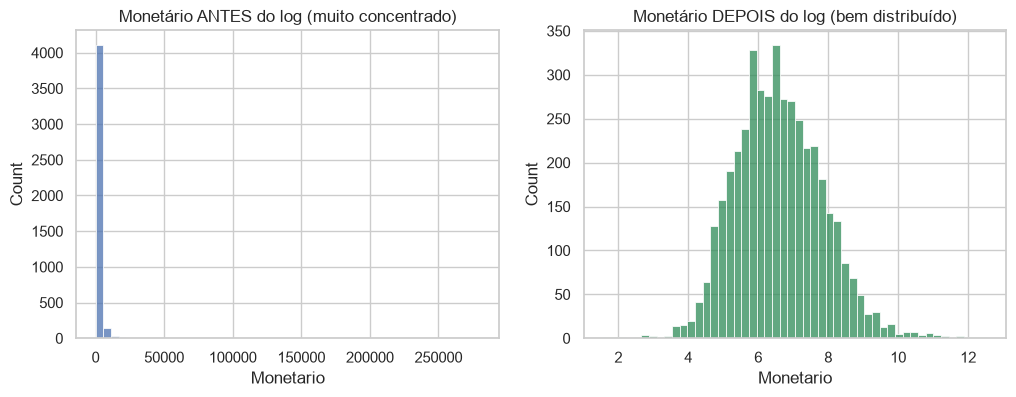

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(rfm['Monetario'], bins=50, ax=ax[0])
ax[0].set_title('Monetário ANTES do log (muito concentrado)')
sns.histplot(np.log1p(rfm['Monetario']), bins=50, ax=ax[1], color='seagreen')
ax[1].set_title('Monetário DEPOIS do log (bem distribuído)')
plt.show()

In [37]:
rfm_log = np.log1p(rfm)                 # log1p = log(1 + x), funciona mesmo com zero

scaler = StandardScaler()
rfm_padronizado = scaler.fit_transform(rfm_log)

print('Exemplo dos dados padronizados (5 primeiros clientes):')
print(rfm_padronizado[:5].round(2))

Exemplo dos dados padronizados (5 primeiros clientes):
[[ 1.46 -0.96  3.71]
 [-2.04  1.07  1.41]
 [ 0.37  0.39  0.72]
 [-0.62 -0.96  0.7 ]
 [ 1.42 -0.96 -0.61]]


### **4.3 Definição do Número de Grupos (Clusters) ($k$)**
**Método do Cotovelo (Elbow Method / WCSS)**: Avalia a Soma dos Quadrados Intra-cluster (Within-Cluster Sum of Squares — WCSS), que mede o grau de dispersão dos dados em relação ao centroide do seu grupo. O valor ideal de $k$ é identificado no ponto de inflexão da curva ("cotovelo"), a partir do qual o ganho em compactação torna-se marginal.

**Coeficiente de Silhueta (Silhouette Score)**: Mensura a coesão interna e a separação inter-cluster, variando no intervalo de $-1$ a $1$. Quanto mais próximo de $1$, melhor estruturada e bem delimitada está a separação entre os grupos.

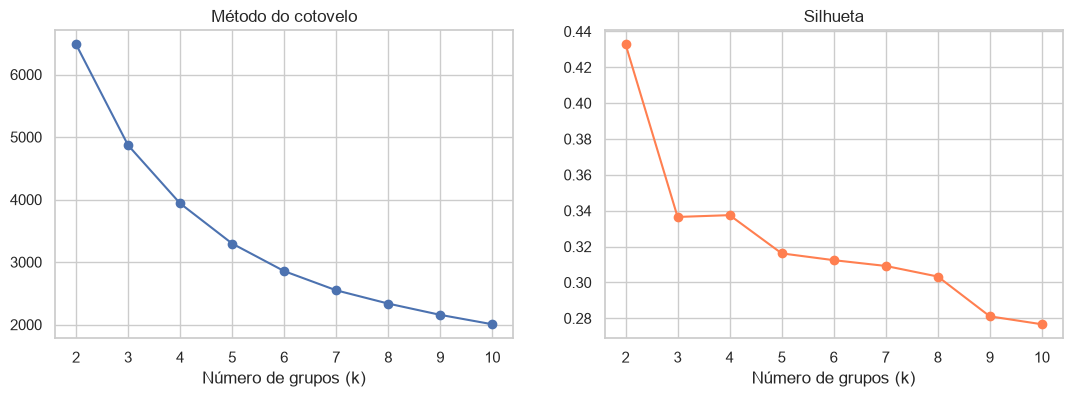

In [38]:
wcss = []
silhueta = []
valores_k = range(2, 11)

for k in valores_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
    modelo.fit(rfm_padronizado)
    wcss.append(modelo.inertia_)
    silhueta.append(silhouette_score(rfm_padronizado, modelo.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(valores_k, wcss, marker='o')
ax[0].set_title('Método do cotovelo')
ax[0].set_xlabel('Número de grupos (k)')
ax[1].plot(valores_k, silhueta, marker='o', color='coral')
ax[1].set_title('Silhueta')
ax[1].set_xlabel('Número de grupos (k)')
plt.show()

A escolha de $k = 4$ fundamenta-se no equilíbrio entre o Método do Cotovelo e o Coeficiente de Silhueta: o gráfico do cotovelo indica uma desaceleração acentuada do erro a partir de $k=4$, enquanto a silhueta mantém uma qualidade de separação estável ($\approx 0,34$). Embora $k=2$ apresente maior silhueta, dividi-los em apenas dois grupos traz pouco valor prático para o negócio, tornando a solução com 4 clusters a mais adequada para estratégias diretas de marketing e retenção

### 4.4 Criar os grupos

In [39]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm['Grupo'] = kmeans.fit_predict(rfm_padronizado)

rfm['Grupo'].value_counts()

Grupo
1    1622
3    1166
2     837
0     713
Name: count, dtype: int64

### 4.5 Entender cada grupo

Calculamos a média de R, F e M de cada grupo e quanto cada um representa em clientes e receita.

In [40]:
perfil = rfm.groupby('Grupo').agg(
    Clientes=('Recencia', 'count'),
    Recencia_media=('Recencia', 'mean'),
    Frequencia_media=('Frequencia', 'mean'),
    Gasto_medio=('Monetario', 'mean'),
    Receita_total=('Monetario', 'sum')
)
perfil['% clientes'] = perfil['Clientes'] / perfil['Clientes'].sum() * 100
perfil['% receita'] = perfil['Receita_total'] / perfil['Receita_total'].sum() * 100

perfil.sort_values('Gasto_medio', ascending=False)

,Clientes,Recencia_media,Frequencia_media,Gasto_medio,Receita_total,% clientes,% receita
Grupo,,,,,,,
0,713,12.17,13.75,"8,088.02","5,766,757.07",16.44,64.89
3,1166,71.64,4.08,"1,801.78","2,100,873.02",26.88,23.64
2,837,17.70,2.19,557.32,"466,479.03",19.29,5.25
1,1622,181.51,1.32,341.00,"553,099.77",37.39,6.22


**Dando nome aos grupos**

Os números dos grupos (0, 1, 2, 3) são aleatórios e podem mudar de computador para computador. Por isso damos os nomes olhando o **perfil**:
- **Clientes de Alto Valor (High-Value):** recência baixa, frequência e gasto altos
- **Clientes Recorrentes em Declínio:** frequência e gasto médios, mas estão há um tempo sem comprar
- **Novos Compradores/Potenciais:** compraram há pouco tempo, mas poucas vezes
- **Inativos / Perdidos:** recência alta (sumiram) e gasto baixo

O código abaixo faz isso automaticamente.

In [41]:
# 1) O grupo com maior gasto médio é o VIP; o de menor gasto médio é o Inativo
ordem = perfil.sort_values('Gasto_medio', ascending=False).index.tolist()
vip, meio1, meio2, inativo = ordem

# 2) Dos dois grupos do meio, o que comprou mais recentemente é o "Recentes"
if perfil.loc[meio1, 'Recencia_media'] < perfil.loc[meio2, 'Recencia_media']:
    recentes, em_risco = meio1, meio2
else:
    recentes, em_risco = meio2, meio1

nomes_grupos = {vip: 'Clientes de Alto Valor (High-Value)', em_risco: 'Clientes Recorrentes em Declínio',
                recentes: 'Novos Compradores/Potenciais', inativo: 'Inativos / Perdidos'}

rfm['Segmento'] = rfm['Grupo'].map(nomes_grupos)
perfil.index = perfil.index.map(nomes_grupos)
perfil.round(1)

,Clientes,Recencia_media,Frequencia_media,Gasto_medio,Receita_total,% clientes,% receita
Grupo,,,,,,,
Clientes de Alto Valor (High-Value),713,12.20,13.80,"8,088.00","5,766,757.10",16.40,64.90
Inativos / Perdidos,1622,181.50,1.30,341.00,"553,099.80",37.40,6.20
Novos Compradores/Potenciais,837,17.70,2.20,557.30,"466,479.00",19.30,5.20
Clientes Recorrentes em Declínio,1166,71.60,4.10,"1,801.80","2,100,873.00",26.90,23.60


### 4.6 Visualizar os grupos

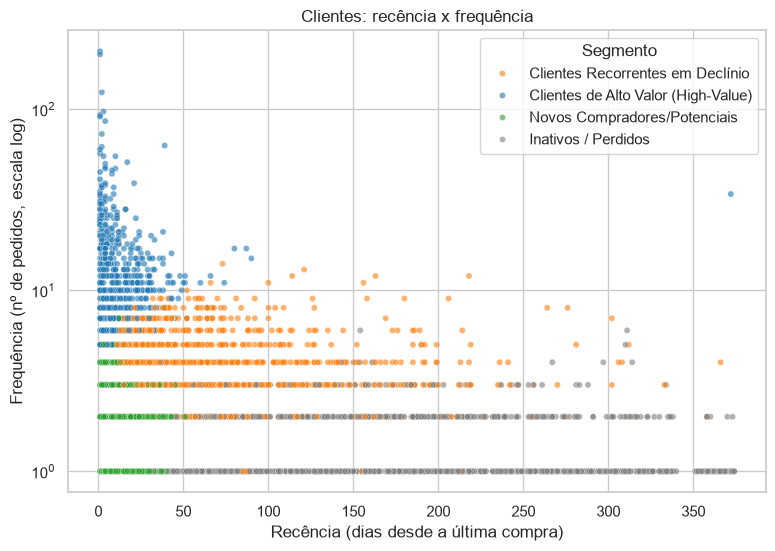

In [42]:
cores = {'Clientes de Alto Valor (High-Value)': 'tab:blue', 'Clientes Recorrentes em Declínio': 'tab:orange',
         'Novos Compradores/Potenciais': 'tab:green', 'Inativos / Perdidos': 'tab:gray'}

plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x='Recencia', y='Frequencia', hue='Segmento',
                palette=cores, alpha=0.6, s=20)
plt.yscale('log')            # escala log para enxergar melhor
plt.title('Clientes: recência x frequência')
plt.xlabel('Recência (dias desde a última compra)')
plt.ylabel('Frequência (nº de pedidos, escala log)')
plt.show()

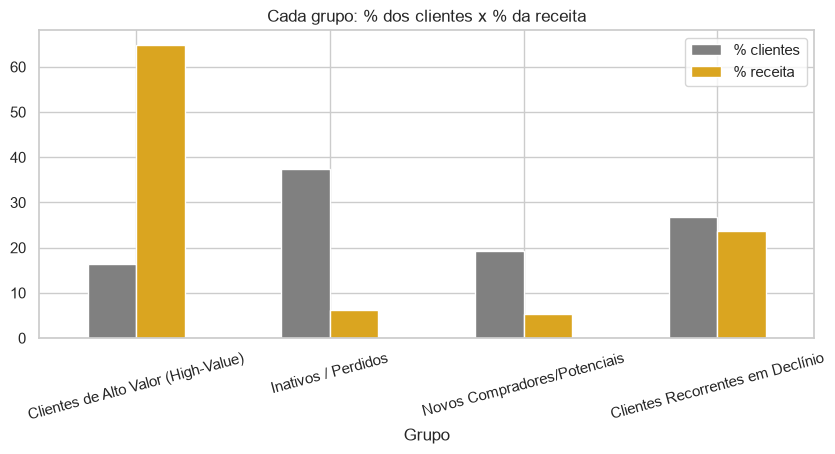

In [43]:
perfil[['% clientes', '% receita']].plot(kind='bar', figsize=(10, 4), color=['gray', 'goldenrod'])
plt.title('Cada grupo: % dos clientes x % da receita')
plt.xticks(rotation=15)
plt.show()

**O que vemos:** o grupo **Clientes de Alto Valor (High-Value)	** tem poucos clientes (cerca de 16%), mas gera a **maior parte da receita** (cerca de 65%). Os **Inativos** são muitos (cerca de 37%), mas trazem pouca receita.

### 4.7 Estratégia para cada grupo

| Grupo | Estratégia |
|---|---|
| **Clientes de Alto Valor (High-Value)** | Implantação de programa de fidelidade, isenção de frete, acesso antecipado às coleções sazonais (Natal) e atendimento VIP exclusivo. |
| **Clientes Recorrentes em Declínio** | Campanhas de Reconquista de Clientes via e-mail marketing personalizadas com base no histórico de compras, aliadas a cupons com gatilhos de escassez (prazo limitado). |
| **Novos Compradores/Potenciais** | Estruturação de fluxo de boas-vindas (onboarding), incentivo à segunda conversão e algoritmos de recomendação no formato "compre junto". |
| **Inativos / Perdidos** | Disparos automatizados e escaláveis em datas comemorativas de alta relevância (como liquidações e Natal), minimizando o custo de aquisição/reativação. |

In [44]:
# Salva a lista de clientes com seu segmento (útil para o time de marketing)
rfm.to_csv('clientes_segmentados.csv')
print('Arquivo clientes_segmentados.csv salvo!')

Arquivo clientes_segmentados.csv salvo!


# **Passo 5: Conclusões e recomendações**

### **5.1 Conclusões:**

**Comportamento de Compra:**  Foco em clientes empresariais/revendedores, com pedidos volumosos concentrados no horário comercial e volume operacional reduzido aos domingos.

**Sazonalidade e Geografia:** Concentração de vendas no Reino Unido e dependência do quadrimestre final do ano (pico entre setembro e novembro).

**Distribuição de Receita:** Forte assimetria na base, com $16\%$ dos clientes de alto valor a responderem por $65\%$ do faturamento total.

**Padrões e Cancelamentos:** Taxa de $16\%$ de cancelamentos em faturas (ajustes de grandes pedidos e erros de digitação) e preferência por aquisição de coleções completas.

### **5.2 Plano de Ação:**

**Recomendado Controle de Ruído Operacional**: Implementar checagem automática para pedidos com volumes atípicos para estancar os $16\%$ de cancelamentos.

**Maximização de LTV (Clientes VIP)**: Oferecer benefícios exclusivos e catálogo antecipado de Natal para a fatia de $16\%$ dos clientes que garante $65\%$ da receita.

**Aumento do Ticket Médio:** }Utilizar algoritmos de recomendação baseados nas coleções (cross-sell) e descontos por lote/quantidade (up-sell).


**Aproveitamento Sazonal:** Disparar campanhas de win-back para reativar clientes em declínio no terceiro trimestre, garantindo tração máxima antes do pico de vendas.